# Trabajo Práctico N° 2

**Materia:** Minería de Datos
**Año:** 2026
**Integrantes:** Renna y Esparza

**Parte A:** regresión sobre `1000_Companies.csv`, estimando la variable `Profit`.
**Parte B:** clasificación sobre `drugType.csv`, estimando la variable `Droga`.

Todos los modelos y particiones usan `random_state=63`.

## Configuración

In [1]:
# Manejo de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

# Modelos y métricas
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Semilla que indica el enunciado, usada en particiones y modelos
SEMILLA = 63

## Parte A: regresión

### A1. Preparación de los datos

Trabajamos con `1000_Companies.csv`, que reúne los gastos y la ganancia de 1000 empresas. La variable a estimar es `Profit`.

In [2]:
empresas = pd.read_csv("1000_Companies.csv")

print("Tabla 1. Primeras filas del conjunto de empresas")
empresas.head()

Tabla 1. Primeras filas del conjunto de empresas


,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
empresas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 39.2 KB


In [4]:
print("Tabla 2. Medidas resumen de las variables numéricas")
empresas.describe()

Tabla 2. Medidas resumen de las variables numéricas


,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


El conjunto tiene **1000 muestras** y 5 columnas, sin ningún valor faltante:

- Tres gastos numéricos: `RyD_Spend` (investigación y desarrollo), `Administration` y `MarketingSpend`.
- Una variable categórica, `State`, con el estado donde opera la empresa.
- La variable objetivo, `Profit`.

En las medidas resumen aparecen dos cuestiones para revisar. La primera es que `Profit` alcanza un máximo de 476.485 cuando el percentil 75 es 155.577, y lo mismo ocurre con `Administration` (máximo 321.652 contra 129.139 en el percentil 75): hay valores muy por encima del resto. La segunda es que `RyD_Spend` y `MarketingSpend` tienen mínimos en 0, que no son errores sino empresas que no invirtieron en ese rubro.

In [5]:
print("Filas duplicadas:", empresas.duplicated().sum())

print("Tabla 3. Filas repetidas")
empresas[empresas.duplicated(keep=False)]

Filas duplicadas: 1
Tabla 3. Filas repetidas


,RyD_Spend,Administration,MarketingSpend,State,Profit
335,84533.0,122941.3141,231885.6935,California,121248.7116
755,84533.0,122941.3141,231885.6935,California,121248.7116


Hay un par de filas idénticas en las cinco columnas. Como en el TP anterior, las tomamos como un registro cargado dos veces y conservamos una sola aparición: de lo contrario esa empresa pesaría el doble al entrenar y podría quedar a la vez en entrenamiento y en test, lo que inflaría artificialmente el rendimiento medido.

In [6]:
empresas = empresas.drop_duplicates()
print("Muestras luego de eliminar duplicados:", len(empresas))

Muestras luego de eliminar duplicados: 999


#### Distribuciones

**Hipótesis previa:** si los gastos impulsan la ganancia, esperamos que las empresas se distribuyan de forma pareja a lo largo del rango de gastos y que `Profit` acompañe esa dispersión.

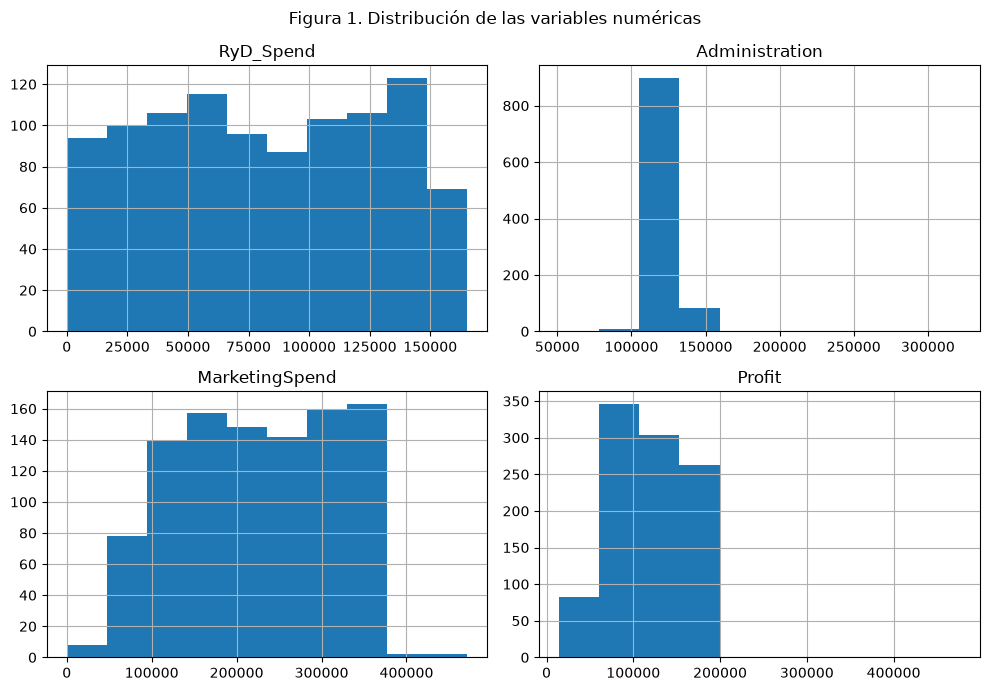

In [7]:
num_cols = ["RyD_Spend", "Administration", "MarketingSpend", "Profit"]

empresas[num_cols].hist(figsize=(10, 7))
plt.suptitle("Figura 1. Distribución de las variables numéricas")
plt.tight_layout()
plt.show()

La hipótesis se cumple parcialmente:

- **`RyD_Spend` y `MarketingSpend`** están repartidos de manera bastante uniforme a lo largo de todo su rango, sin una concentración marcada.
- **`Administration`** es la excepción: casi todas las empresas gastan entre 100.000 y 150.000, con una cola muy delgada que llega hasta 320.000.
- **`Profit`** se concentra entre 50.000 y 200.000, con unos pocos valores que se despegan hasta 476.485.

#### Correlaciones

**Hipótesis previa:** los tres gastos deberían relacionarse positivamente con la ganancia.

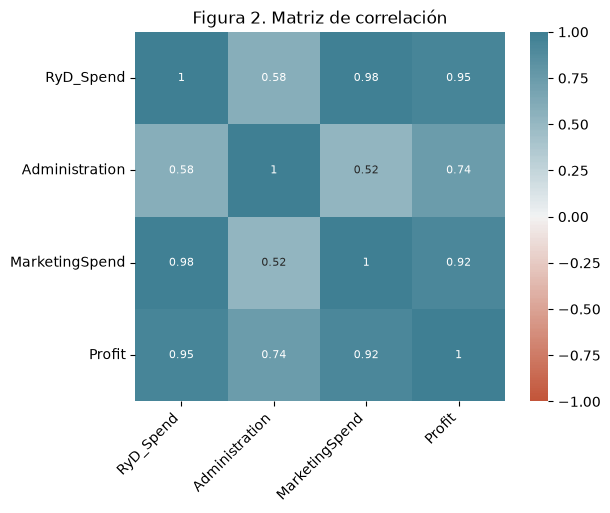

In [8]:
def plot_correlation_heatmap(corr, title):
    ax = sns.heatmap(
        corr,
        vmin=-1, vmax=1, center=0,
        cmap=sns.diverging_palette(20, 220, n=200),
        square=True,
        annot = True,
        annot_kws = {'size': 8})
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=45,
        horizontalalignment='right')
    plt.title(title)
    plt.show()


plot_correlation_heatmap(empresas[num_cols].corr(), "Figura 2. Matriz de correlación")

La hipótesis se confirma, pero con intensidades muy distintas:

- **`RyD_Spend` es la que más se relaciona con la ganancia (0.95)**, seguida de `MarketingSpend` (0.92).
- `Administration` queda bastante más atrás (0.74).
- Entre los predictores hay un dato relevante: **`RyD_Spend` y `MarketingSpend` están correlacionados entre sí en 0.98**, es decir que aportan prácticamente la misma información.

Para ver si esas correlaciones se traducen en una relación aprovechable, graficamos cada gasto contra la ganancia.

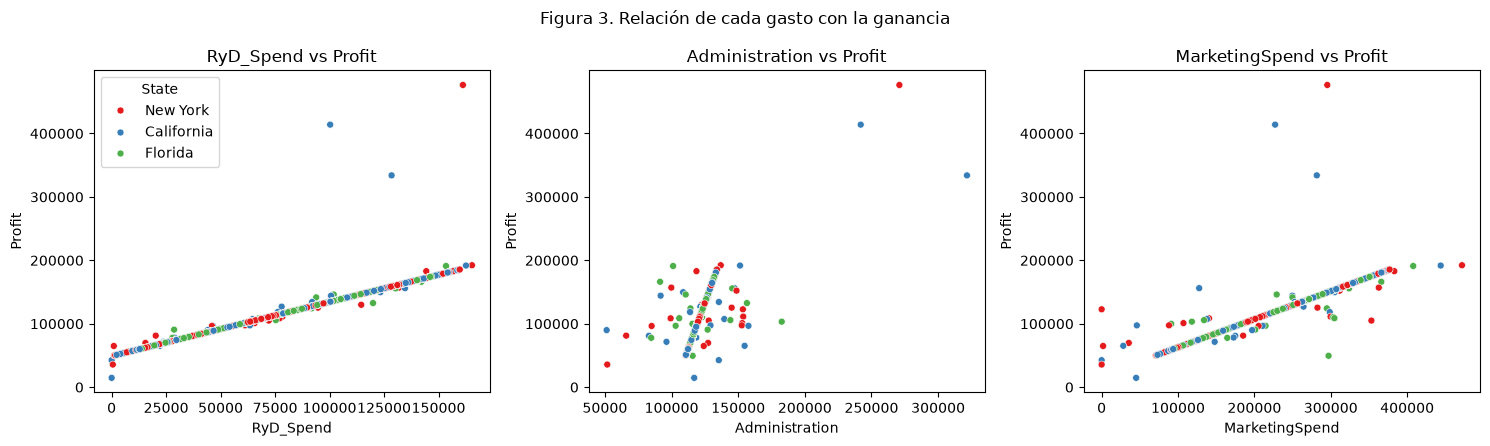

In [9]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4.5))

for ax, col in zip(axes, ["RyD_Spend", "Administration", "MarketingSpend"]):
    sns.scatterplot(data=empresas, x=col, y="Profit", hue="State", palette="Set1", s=25, ax=ax,
                    legend=(col == "RyD_Spend"))
    ax.set_title(f"{col} vs Profit")

plt.suptitle("Figura 3. Relación de cada gasto con la ganancia")
plt.tight_layout()
plt.show()

El gráfico muestra algo que la correlación por sí sola no dejaba ver:

- **`RyD_Spend` contra `Profit` forma casi una recta.** Los puntos se alinean de manera tan ajustada que la ganancia queda prácticamente determinada por ese gasto.
- **`Administration` contra `Profit` es una nube sin forma.** Su correlación de 0.74 no se traduce en una relación utilizable: empresas con gastos administrativos parecidos tienen ganancias muy distintas.
- **`MarketingSpend` sigue la misma recta que `RyD_Spend`**, lo que es coherente con el 0.98 de correlación entre ambos.
- **El estado no diferencia nada**: los tres colores están mezclados a lo largo de toda la recta.

También se ven tres puntos muy por encima de la recta, los mismos que se despegaban en la Tabla 2.

#### Valores atípicos

Contamos los valores fuera del rango intercuartílico (1.5 × IQR) en cada variable numérica.

In [10]:
for col in num_cols:
    q1 = empresas[col].quantile(0.25)
    q3 = empresas[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = empresas[(empresas[col] < lower_bound) | (empresas[col] > upper_bound)]
    print(f"{col}: {len(outliers)} atípicos ({len(outliers)/len(empresas)*100:.1f}%) | límite superior {upper_bound:,.0f}")

print()
print("Tabla 4. Empresas con mayor ganancia")
empresas.nlargest(3, "Profit")

RyD_Spend: 0 atípicos (0.0%) | límite superior 246,861
Administration: 22 atípicos (2.2%) | límite superior 147,895
MarketingSpend: 0 atípicos (0.0%) | límite superior 545,121
Profit: 3 atípicos (0.3%) | límite superior 260,225

Tabla 4. Empresas con mayor ganancia


,RyD_Spend,Administration,MarketingSpend,State,Profit
999,161181.72,270939.86,295442.17,New York,476485.43
997,100275.47,241926.31,227142.82,California,413956.48
998,128456.23,321652.14,281692.32,California,333962.19


Aparecen dos situaciones distintas, y las tratamos de manera diferente.

**`Profit`: 3 valores atípicos, que eliminamos.** Son las tres últimas filas del archivo (Tabla 4) y rompen a la vez dos patrones: su gasto administrativo duplica o triplica el promedio de 122.963 que muestra la Tabla 2, y en la Figura 3 quedan muy por encima de la recta que forman las demás empresas. Son 3 casos sobre 999 (0.3%).

El motivo para eliminarlas es que se trata de la **variable objetivo**: si quedan en el conjunto de test, los errores medios se disparan por esas tres solas; si quedan en entrenamiento, el árbol dedica divisiones a casos que no responden al patrón del resto.

**`Administration`: 22 valores atípicos, que conservamos.** Descontadas esas tres empresas, los restantes son gastos administrativos algo más altos de lo habitual, sin nada que indique que sean errores. Tampoco es la variable que hay que predecir, así que un valor alto no distorsiona la medición del error.

In [11]:
q1 = empresas["Profit"].quantile(0.25)
q3 = empresas["Profit"].quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)

empresas = empresas[empresas["Profit"] <= limite_superior]
print(f"Muestras luego de eliminar las empresas con ganancia atípica: {len(empresas)}")
print()
print("Tabla 5. Medidas resumen luego de la limpieza")
empresas[num_cols].describe()

Muestras luego de eliminar las empresas con ganancia atípica: 996

Tabla 5. Medidas resumen luego de la limpieza


,RyD_Spend,Administration,MarketingSpend,Profit
count,996.000000,996.000000,996.000000,996.000000
mean,81520.563032,122496.423682,226073.188168,118675.212695
std,46535.141677,9144.756564,91718.887094,39808.331643
min,0.000000,51283.140000,0.000000,14681.400000
25%,43056.000000,116636.180475,150136.039475,85839.615710
50%,79401.000000,122377.380650,223809.759850,117321.534150
75%,124079.000000,129060.069850,309128.511625,155032.518175
max,165349.200000,182645.560000,471784.100000,192261.830000


El conjunto queda con **996 empresas**. En la Tabla 5 se ve que la ganancia máxima pasa de 476.485 a 192.261 y el gasto administrativo máximo de 321.652 a 182.646, de modo que ambas variables quedan dentro de rangos coherentes con el resto de los datos.

#### Separación en entrenamiento y test

Generamos las dos particiones que pide el enunciado, 80/20 y 70/30, con `random_state=63`.

La codificación y la estandarización se aplican **después** de separar, y se ajustan únicamente con el conjunto de entrenamiento. De lo contrario, los valores usados para transformar los datos se calcularían también con el test, y el modelo estaría entrenándose con información de las muestras con las que después se lo evalúa.

In [12]:
X = empresas.drop(columns="Profit")
y = empresas["Profit"]

num_vars = ["RyD_Spend", "Administration", "MarketingSpend"]
cat_vars = ["State"]


def preparar(test_size):
    Xtrn, Xtst, ytrn, ytst = train_test_split(X, y, test_size=test_size,
                                              random_state=SEMILLA, shuffle=True)

    # Codificación: State no tiene orden, por lo que se expande en una columna por estado
    enc = OneHotEncoder(sparse_output=False, dtype=int).set_output(transform="pandas")
    enc.fit(Xtrn[cat_vars])
    Xtrn = pd.concat([Xtrn[num_vars], enc.transform(Xtrn[cat_vars])], axis=1)
    Xtst = pd.concat([Xtst[num_vars], enc.transform(Xtst[cat_vars])], axis=1)

    # Estandarización de las numéricas, ajustada solo con el entrenamiento
    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(Xtrn[num_vars])
    Xtrn_std, Xtst_std = Xtrn.copy(), Xtst.copy()
    Xtrn_std[num_vars] = scaler.transform(Xtrn[num_vars])
    Xtst_std[num_vars] = scaler.transform(Xtst[num_vars])

    return Xtrn, Xtst, ytrn, ytst, Xtrn_std, Xtst_std


particiones = {"80/20": preparar(0.2), "70/30": preparar(0.3)}

for nombre, (Xtrn, Xtst, _, _, _, _) in particiones.items():
    print(f"{nombre}: entrenamiento {len(Xtrn)} muestras | test {len(Xtst)} muestras")

print()
print("Tabla 6. Variables luego de codificar State")
particiones["80/20"][0].head()

80/20: entrenamiento 796 muestras | test 200 muestras
70/30: entrenamiento 697 muestras | test 299 muestras

Tabla 6. Variables luego de codificar State


,RyD_Spend,Administration,MarketingSpend,State_California,State_Florida,State_New York
398,12412.0,112290.1563,92728.02707,1,0,0
794,12564.0,112312.6043,93021.31149,1,0,0
102,127529.0,129291.1592,314846.59290,0,1,0
883,64529.0,119987.0323,193287.92090,1,0,0
219,10758.0,112045.8860,89536.62956,1,0,0


Las particiones quedan con 796 y 200 muestras la primera, y 697 y 299 la segunda, sobre las 996 empresas.

`State` se reemplazó por tres columnas de 0 y 1, una por estado (Tabla 6). Se usa esta codificación, y no una columna con valores 0, 1 y 2, porque los estados no tienen un orden: asignarles números consecutivos implicaría que Florida está "más lejos" de New York que California, lo cual no significa nada.

In [13]:
resumen_std = pd.DataFrame({
    "media entrenamiento": particiones["80/20"][4][num_vars].mean(),
    "desvío entrenamiento": particiones["80/20"][4][num_vars].std(),
    "media test": particiones["80/20"][5][num_vars].mean(),
    "desvío test": particiones["80/20"][5][num_vars].std(),
}).round(3)

print("Tabla 7. Efecto de la estandarización en la partición 80/20")
resumen_std

Tabla 7. Efecto de la estandarización en la partición 80/20


,media entrenamiento,desvío entrenamiento,media test,desvío test
RyD_Spend,-0.0,1.001,0.086,1.047
Administration,-0.0,1.001,0.007,1.138
MarketingSpend,0.0,1.001,0.097,1.057


En el entrenamiento las tres variables quedan con media 0 y desvío 1. En el test, en cambio, las medias no son exactamente 0 (0.086, 0.007 y 0.097) ni los desvíos exactamente 1.

Eso es lo esperado y confirma que la estandarización se ajustó solo con el entrenamiento: al test se le restó la media del entrenamiento, no la suya. Si las cuatro columnas hubieran dado 0 y 1, sería señal de que el cálculo se hizo con todos los datos juntos.

Los árboles de decisión de la próxima actividad se entrenan con las variables **sin estandarizar**, como en los notebooks de la unidad 4, para que los umbrales del árbol se puedan leer en las unidades originales. Las versiones estandarizadas quedan calculadas, tal como pide el enunciado.

### A2. Árbol de decisión para regresión

**Hipótesis previa:** en la Figura 3 la ganancia quedaba casi determinada por `RyD_Spend`, de modo que esperamos un error de estimación bajo frente a la escala de `Profit` (Tabla 5) y que el árbol se apoye principalmente en esa variable.

Exploramos las combinaciones de los tres hiperparámetros con `GridSearchCV`, que evalúa cada una por validación cruzada **dentro del conjunto de entrenamiento**. El test queda reservado para la evaluación final. Se usan los mismos valores de la grilla del notebook de la unidad 4, y como criterio de selección el error cuadrático medio, una de las métricas que pide reportar el enunciado.

In [14]:
grilla = {
    "max_depth": [3, 5, 10, None],
    "min_samples_leaf": [1, 5, 10],
    "min_samples_split": [2, 5, 10],
}

busquedas = {}
for nombre, (Xtrn, Xtst, ytrn, ytst, _, _) in particiones.items():
    busqueda = GridSearchCV(DecisionTreeRegressor(random_state=SEMILLA), grilla,
                            cv=5, scoring="neg_mean_squared_error")
    busqueda.fit(Xtrn, ytrn)
    busquedas[nombre] = busqueda
    arbol = busqueda.best_estimator_
    print(f"{nombre} -> {busqueda.best_params_}")
    print(f"   RMSE de validación cruzada: {np.sqrt(-busqueda.best_score_):,.0f}"
          f" | profundidad alcanzada: {arbol.get_depth()} | hojas: {arbol.get_n_leaves()}")

resultados_cv = pd.DataFrame(busquedas["80/20"].cv_results_)
resultados_cv["RMSE_cv"] = np.sqrt(-resultados_cv["mean_test_score"])

print()
print("Tabla 8. Mejores combinaciones en la partición 80/20")
resultados_cv.sort_values("rank_test_score")[
    ["param_max_depth", "param_min_samples_leaf", "param_min_samples_split", "RMSE_cv"]
].head(6).round(0)

80/20 -> {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
   RMSE de validación cruzada: 2,241 | profundidad alcanzada: 10 | hojas: 141


70/30 -> {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
   RMSE de validación cruzada: 2,435 | profundidad alcanzada: 8 | hojas: 106

Tabla 8. Mejores combinaciones en la partición 80/20


,param_max_depth,param_min_samples_leaf,param_min_samples_split,RMSE_cv
29,None,1,10,2241.0
20,10,1,10,2241.0
23,10,5,10,2261.0
22,10,5,5,2261.0
31,None,5,5,2261.0
21,10,5,2,2261.0


Las dos particiones coinciden en `max_depth=10` y difieren en los otros dos: la 80/20 elige `min_samples_leaf=1` con `min_samples_split=10`, y la 70/30 `min_samples_leaf=5` con `min_samples_split=2`. Los árboles resultantes tienen 141 y 106 hojas.

En la Tabla 8 varias combinaciones empatan con el mismo RMSE de validación. Las dos primeras (2.241) se diferencian solo en `max_depth`: 10 o sin límite dan el mismo resultado. Las cuatro siguientes empatan en 2.261 con distintos valores de `min_samples_split`, lo que indica que ese hiperparámetro casi no incide: las hojas ya quedan limitadas por `min_samples_leaf`.

Las dos primeras filas de la Tabla 8 tienen un RMSE de 2.241 y las cuatro siguientes de 2.261: 20 de diferencia, menos del 1%. Dentro de esta grilla, entonces, la elección entre una combinación y otra apenas cambia el resultado.

In [15]:
importancias = pd.DataFrame({
    "variable": particiones["80/20"][0].columns,
    "importancia": busquedas["80/20"].best_estimator_.feature_importances_,
}).sort_values("importancia", ascending=False)

print("Tabla 9. Importancia de cada variable en el árbol (partición 80/20)")
importancias.round(4)

Tabla 9. Importancia de cada variable en el árbol (partición 80/20)


,variable,importancia
0,RyD_Spend,0.9890
2,MarketingSpend,0.0065
1,Administration,0.0045
3,State_California,0.0000
4,State_Florida,0.0000
5,State_New York,0.0000


La hipótesis se confirma: **`RyD_Spend` concentra el 98.9% de la importancia**. `MarketingSpend` aporta menos del 1% y `Administration` prácticamente nada, mientras que las tres columnas de `State` quedan en 0, es decir que el árbol nunca las usó para dividir.

Esto es coherente con la Figura 3, donde el gasto en investigación formaba una recta con la ganancia, el gasto administrativo era una nube y los estados estaban mezclados.

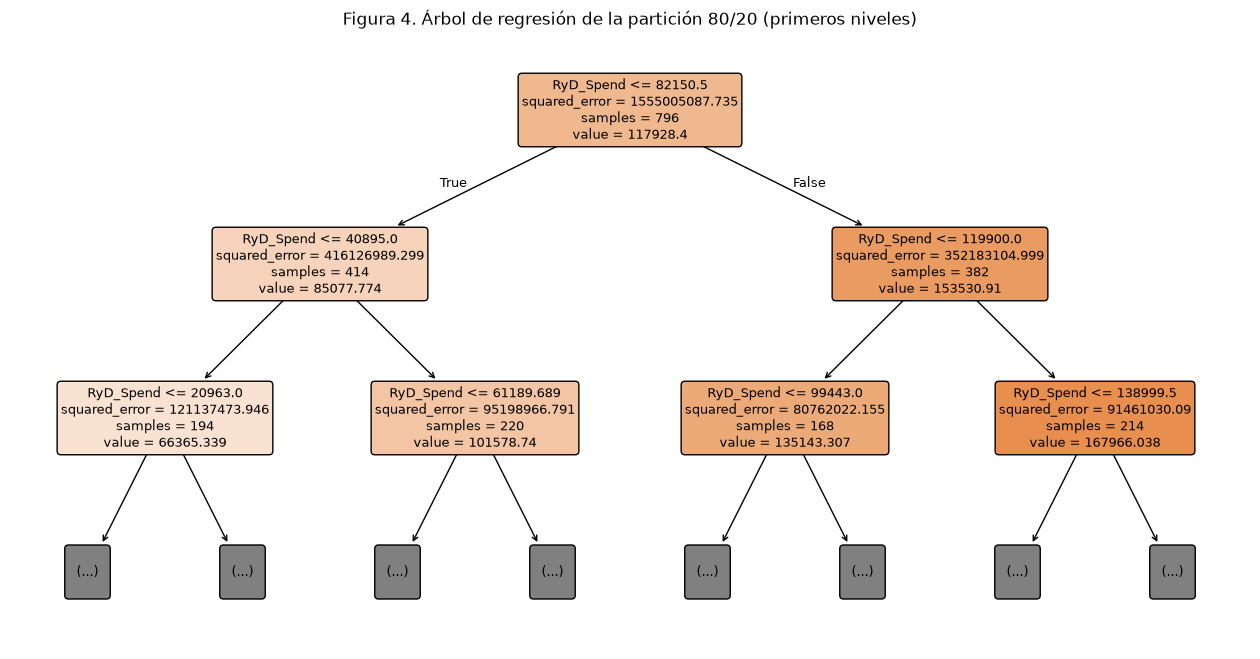

In [16]:
plt.figure(figsize=(16, 8))
plot_tree(busquedas["80/20"].best_estimator_, max_depth=2,
          feature_names=particiones["80/20"][0].columns,
          filled=True, rounded=True, fontsize=9)
plt.title("Figura 4. Árbol de regresión de la partición 80/20 (primeros niveles)")
plt.show()

El árbol completo tiene 141 hojas, por lo que se muestran sus primeros niveles: con el árbol entero las etiquetas quedan ilegibles.

Todas las divisiones visibles usan `RyD_Spend`, y los umbrales se leen directamente en pesos porque el modelo se entrenó con las variables sin estandarizar. La primera separa en 82.150,5, dejando 414 empresas a un lado con una ganancia media de 117.928 y 382 al otro. Los cortes siguientes subdividen esos tramos en 40.895 y 119.900, siempre sobre la misma variable.

El `squared_error` baja de 1.555 millones en la raíz a 416 y 352 millones en el segundo nivel, es decir que cada división deja grupos con ganancias cada vez más parecidas entre sí.

In [17]:
filas = []
for nombre, (Xtrn, Xtst, ytrn, ytst, _, _) in particiones.items():
    pred = busquedas[nombre].best_estimator_.predict(Xtst)
    mse = mean_squared_error(ytst, pred)
    filas.append({
        "partición": nombre,
        "muestras de test": len(ytst),
        "MAE": mean_absolute_error(ytst, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    })

metricas_reg = pd.DataFrame(filas)

print("Tabla 10. Métricas sobre los conjuntos de test")
metricas_reg.round(2)

Tabla 10. Métricas sobre los conjuntos de test


,partición,muestras de test,MAE,MSE,RMSE
0,80/20,200,997.20,12853559.57,3585.19
1,70/30,299,949.77,8354923.35,2890.49


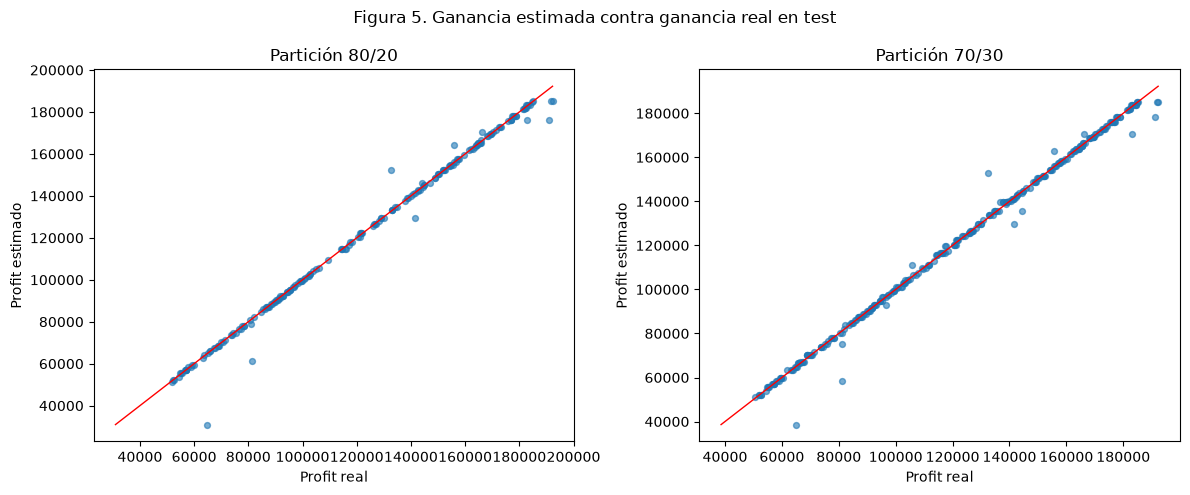

In [18]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

for ax, (nombre, (Xtrn, Xtst, ytrn, ytst, _, _)) in zip(axes, particiones.items()):
    pred = busquedas[nombre].best_estimator_.predict(Xtst)
    ax.scatter(ytst, pred, s=18, alpha=0.6)
    limites = [min(ytst.min(), pred.min()), max(ytst.max(), pred.max())]
    ax.plot(limites, limites, color="red", linewidth=1)
    ax.set_xlabel("Profit real")
    ax.set_ylabel("Profit estimado")
    ax.set_title(f"Partición {nombre}")

plt.suptitle("Figura 5. Ganancia estimada contra ganancia real en test")
plt.tight_layout()
plt.show()

La hipótesis se confirma. El MAE es de 997 en la partición 80/20 y de 950 en la 70/30, frente a una ganancia media de 118.675 (Tabla 5): el error representa alrededor del 1% de lo que se quiere estimar.

El RMSE es mucho mayor que el MAE en ambos casos (3.585 y 2.890 contra 997 y 950). Esa diferencia indica que la mayoría de las estimaciones tiene un error muy chico y unas pocas se desvían bastante, como se ve en la Figura 5: los puntos se apoyan sobre la diagonal salvo un puñado que se aleja.

Entre las dos particiones, la 70/30 obtiene mejores valores en las tres métricas pese a entrenar con 99 empresas menos. La diferencia no indica que una partición sea mejor que la otra: con unos pocos casos difíciles en el test alcanza para mover el promedio, y el test de la 80/20 tiene 200 muestras contra 299 de la otra.

## Parte B: clasificación

### B3. Preparación de los datos

Trabajamos con `drugType.csv`, que reúne datos de 200 pacientes y la droga que se les indicó. La variable a estimar es `Droga`.

In [19]:
pacientes = pd.read_csv("drugType.csv")

print("Tabla 11. Primeras filas del conjunto de pacientes")
pacientes.head()

Tabla 11. Primeras filas del conjunto de pacientes


,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


In [20]:
pacientes.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


In [21]:
print("Filas duplicadas:", pacientes.duplicated().sum())
print()
print("Tabla 12. Medidas resumen de las variables numéricas")
pacientes.describe()

Filas duplicadas: 0

Tabla 12. Medidas resumen de las variables numéricas


,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


El conjunto tiene **200 pacientes** y 6 columnas, sin valores faltantes ni filas duplicadas:

- Dos variables numéricas: `Edad` (de 15 a 74 años) y `Na_a_K`, la relación entre sodio y potasio en sangre (de 6.27 a 38.25).
- Tres categóricas: `Sexo`, `BP` (presión arterial) y `Colesterol`.
- La variable objetivo, `Droga`.

#### Distribución de la variable objetivo

**Hipótesis previa:** al tratarse de indicaciones médicas, es esperable que algunas drogas se receten mucho más que otras, es decir que las clases no estén balanceadas.

Tabla 13. Balance de clases


,Cantidad,Porcentaje
Droga,,
DrogaY,91,45.5
DrogaX,54,27.0
DrogaA,23,11.5
DrogaC,16,8.0
DrogaB,16,8.0


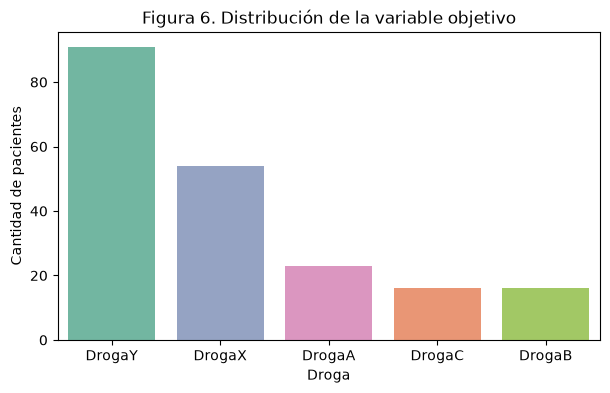

In [22]:
balance = pd.DataFrame({
    "Cantidad": pacientes["Droga"].value_counts(),
    "Porcentaje": (pacientes["Droga"].value_counts(normalize=True) * 100).round(1),
})

print("Tabla 13. Balance de clases")
display(balance)

plt.figure(figsize=(7, 4))
orden_drogas = pacientes["Droga"].value_counts().index
sns.countplot(data=pacientes, x="Droga", order=orden_drogas, hue="Droga",
              palette="Set2", legend=False)
plt.ylabel("Cantidad de pacientes")
plt.title("Figura 6. Distribución de la variable objetivo")
plt.show()

La hipótesis se confirma: las clases están **desbalanceadas**. DrogaY concentra el 45.5% de los casos y DrogaX el 27%, mientras que DrogaC y DrogaB tienen 16 pacientes cada una, un 8%.

Esto condiciona dos decisiones del trabajo:

- Las particiones se hacen **estratificadas**, para que las clases minoritarias estén representadas en ambos conjuntos en la misma proporción. Con 16 casos, un sorteo sin estratificar podría dejar muy pocos en el test.
- Las métricas de precisión y exhaustividad se reportan en **macro**, es decir promediando el valor de cada clase sin pesar por su tamaño, tal como pide el enunciado.

#### Variables numéricas

**Hipótesis previa:** si estas dos variables influyen en la indicación, cada droga debería corresponder a rangos distintos de edad o de la relación sodio-potasio.

Tabla 14. Edad y Na_a_K según la droga


Edad           Na_a_K            
        min  mean max    min  mean   max
Droga                                   
DrogaA   19  35.9  50    6.3  10.9  14.0
DrogaB   51  62.5  74    8.6  11.5  14.2
DrogaC   16  42.5  72    6.8  10.6  14.2
DrogaX   15  44.0  74    6.7  10.7  14.6
DrogaY   15  43.7  74   15.0  22.4  38.2

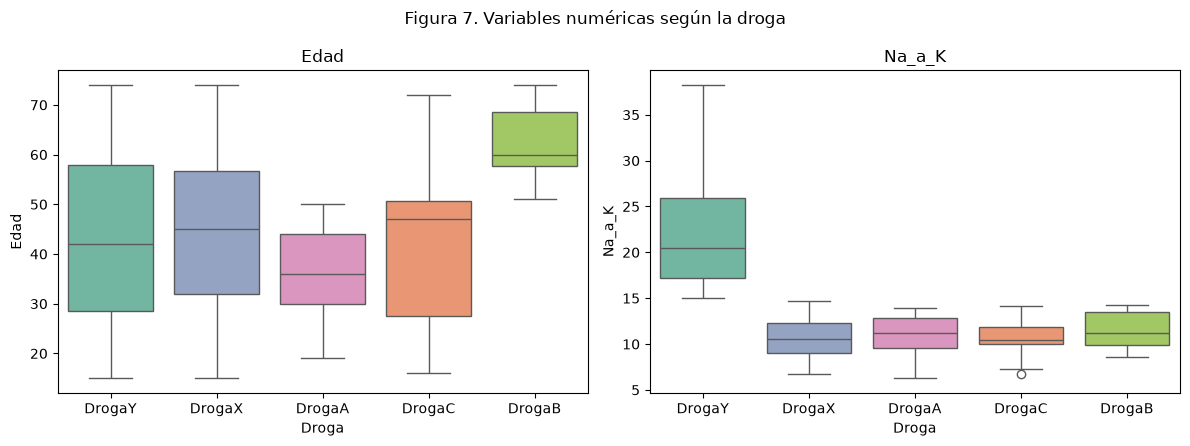

In [23]:
resumen_num = pacientes.groupby("Droga")[["Edad", "Na_a_K"]].agg(["min", "mean", "max"]).round(1)

print("Tabla 14. Edad y Na_a_K según la droga")
display(resumen_num)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

for ax, columna in zip(axes, ["Edad", "Na_a_K"]):
    sns.boxplot(data=pacientes, x="Droga", y=columna, order=orden_drogas,
                hue="Droga", palette="Set2", legend=False, ax=ax)
    ax.set_title(columna)

plt.suptitle("Figura 7. Variables numéricas según la droga")
plt.tight_layout()
plt.show()

La hipótesis se confirma, y con una nitidez llamativa en `Na_a_K`:

- **`Na_a_K` separa por completo a DrogaY.** Su valor mínimo es 15.0 y el de las otras cuatro drogas nunca supera 14.6 (Tabla 14). En la Figura 7 la caja de DrogaY queda entera por encima de las demás, sin superposición.
- **`Edad` distingue a DrogaB**, cuyo mínimo es 51 años mientras las demás arrancan entre 15 y 19. Las otras cuatro tienen rangos de edad muy parecidos entre sí.

Es decir que, por sí sola, `Na_a_K` ya permite identificar a casi la mitad de los pacientes.

#### Variables categóricas

**Hipótesis previa:** la presión arterial y el colesterol son indicadores clínicos, así que esperamos que estén asociados a la droga indicada; el sexo, en cambio, no debería influir.

Sexo contra Droga
Droga  DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Sexo                                         
F           9       6       7      27      47
M          14      10       9      27      44

BP contra Droga
Droga   DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
BP                                            
Alto        23      16       0       0      38
Bajo         0       0      16      18      30
Normal       0       0       0      36      23

Colesterol contra Droga
Droga       DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Colesterol                                        
Alto            12       8      16      20      47
Normal          11       8       0      34      44



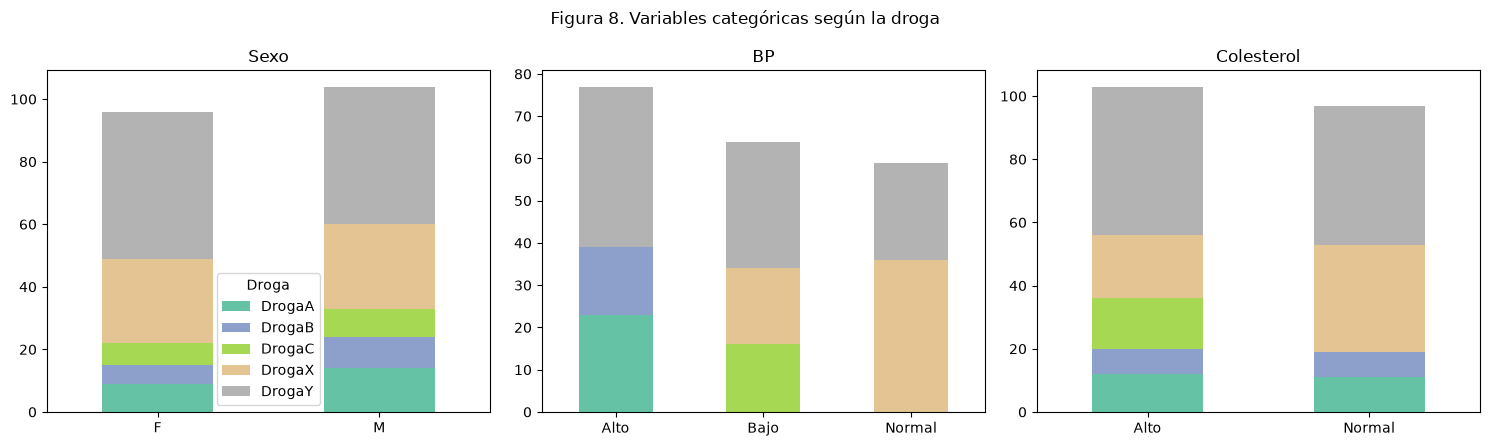

In [24]:
for columna in ["Sexo", "BP", "Colesterol"]:
    print(f"{columna} contra Droga")
    print(pd.crosstab(pacientes[columna], pacientes["Droga"]))
    print()

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4.5))

for ax, columna in zip(axes, ["Sexo", "BP", "Colesterol"]):
    pd.crosstab(pacientes[columna], pacientes["Droga"]).plot(
        kind="bar", stacked=True, ax=ax, colormap="Set2", legend=(columna == "Sexo"))
    ax.set_title(columna)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Figura 8. Variables categóricas según la droga")
plt.tight_layout()
plt.show()

La hipótesis se confirma en las tres variables:

- **`BP` es la más informativa.** DrogaA y DrogaB aparecen **únicamente** con presión alta (23 y 16 casos); DrogaC, únicamente con presión baja (16 casos); y DrogaX, con presión baja o normal, nunca alta.
- **`Colesterol`** separa a DrogaC, que solo aparece con colesterol alto (16 casos).
- **`Sexo` no aporta**: las cinco drogas se reparten de manera pareja entre varones y mujeres, como se ve en el primer panel de la Figura 8.

Combinando lo anterior, se insinúa una estructura de reglas: `Na_a_K` identifica a DrogaY; dentro de los demás, la presión separa los grupos, y la edad distingue DrogaA de DrogaB.

#### Valores atípicos

In [25]:
for columna in ["Edad", "Na_a_K"]:
    q1 = pacientes[columna].quantile(0.25)
    q3 = pacientes[columna].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = pacientes[(pacientes[columna] < lower_bound) | (pacientes[columna] > upper_bound)]
    print(f"{columna}: {len(outliers)} atípicos | límite superior {upper_bound:.1f}")
    if len(outliers) > 0:
        print(outliers["Droga"].value_counts().to_string())

Edad: 0 atípicos | límite superior 98.5
Na_a_K: 8 atípicos | límite superior 32.8
Droga
DrogaY    8


`Edad` no tiene valores atípicos y `Na_a_K` tiene 8, todos pertenecientes a DrogaY.

**No los eliminamos ni los recortamos.** Son los valores altos de la variable que, como muestra la Figura 7, define a esa clase: recortarlos acercaría esos pacientes al rango de las otras drogas y destruiría justamente la información que permite reconocerlos.

#### Codificación y particiones

`BP` y `Colesterol` tienen un orden natural, así que se codifican respetándolo (Bajo < Normal < Alto); `Sexo` es binaria. `Droga` se deja como está: `scikit-learn` acepta etiquetas de texto en la variable objetivo, y así las matrices de confusión se leen con el nombre de cada droga.

Como en la Parte A, el codificador y el escalador se ajustan **solo con el entrenamiento**. Las particiones llevan `stratify` para conservar la proporción de clases.

In [26]:
X_pac = pacientes.drop(columns="Droga")
y_pac = pacientes["Droga"]

num_pac = ["Edad", "Na_a_K"]
cat_pac = ["Sexo", "BP", "Colesterol"]

# Orden explícito de cada categoría
categorias = [
    ["F", "M"],              # Sexo
    ["Bajo", "Normal", "Alto"],  # BP
    ["Normal", "Alto"],      # Colesterol
]


def preparar_pacientes(test_size):
    Xtrn, Xtst, ytrn, ytst = train_test_split(X_pac, y_pac, test_size=test_size,
                                              random_state=SEMILLA, shuffle=True,
                                              stratify=y_pac)

    enc = OrdinalEncoder(categories=categorias).set_output(transform="pandas")
    enc.fit(Xtrn[cat_pac])
    Xtrn[cat_pac] = enc.transform(Xtrn[cat_pac])
    Xtst[cat_pac] = enc.transform(Xtst[cat_pac])

    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(Xtrn[num_pac])
    Xtrn_std, Xtst_std = Xtrn.copy(), Xtst.copy()
    Xtrn_std[num_pac] = scaler.transform(Xtrn[num_pac])
    Xtst_std[num_pac] = scaler.transform(Xtst[num_pac])

    return Xtrn, Xtst, ytrn, ytst, Xtrn_std, Xtst_std


particiones_pac = {"80/20": preparar_pacientes(0.2), "70/30": preparar_pacientes(0.3)}

for nombre, (Xtrn, Xtst, _, _, _, _) in particiones_pac.items():
    print(f"{nombre}: entrenamiento {len(Xtrn)} pacientes | test {len(Xtst)} pacientes")

proporciones = pd.DataFrame({
    "conjunto completo": y_pac.value_counts(normalize=True),
    "train 80/20": particiones_pac["80/20"][2].value_counts(normalize=True),
    "test 80/20": particiones_pac["80/20"][3].value_counts(normalize=True),
    "test 70/30": particiones_pac["70/30"][3].value_counts(normalize=True),
}).round(3) * 100

print()
print("Tabla 15. Porcentaje de cada clase en los conjuntos")
proporciones

80/20: entrenamiento 160 pacientes | test 40 pacientes
70/30: entrenamiento 140 pacientes | test 60 pacientes

Tabla 15. Porcentaje de cada clase en los conjuntos


,conjunto completo,train 80/20,test 80/20,test 70/30
Droga,,,,
DrogaA,11.5,11.2,12.5,11.7
DrogaB,8.0,8.1,7.5,8.3
DrogaC,8.0,8.1,7.5,8.3
DrogaX,27.0,26.9,27.5,26.7
DrogaY,45.5,45.6,45.0,45.0


Las particiones quedan con 160 y 40 pacientes la primera, y 140 y 60 la segunda.

En la Tabla 15 se comprueba que la estratificación funcionó: las proporciones de cada clase en los conjuntos de entrenamiento y de test coinciden con las del conjunto completo. DrogaY se mantiene cerca del 45% en los tres y las clases de 16 pacientes conservan su 8%, lo que asegura que estén representadas en los test.